# Vision Transformer (ViT-B/16), 224 px (R4)

This notebook fine-tunes an **ImageNet-pretrained Vision Transformer** (ViT-B/16, Dosovitskiy et al., 2021) to classify the 200 bird species. It uses the **same photos, splits, augmentation, training loop, protocol and metrics** as [`resnet50_altered_224px.ipynb`](resnet50_altered_224px.ipynb) and [`base_cnn.ipynb`](base_cnn.ipynb), so the only thing that changes is the network. That gives a direct comparison of a pretrained CNN with a pretrained transformer on the same 5,794 test photos.

**Why a ViT:** a CNN looks at small neighbourhoods of pixels first and builds up to whole birds layer by layer. A ViT cuts the photo into 16 × 16-pixel patches and lets every patch compare itself with every other patch from the first layer (self-attention), so it can relate the bill to the tail straight away. It has fewer built-in assumptions about images than a CNN, which means it needs far more data to learn from scratch than our ~30 photos per species. That is why we fine-tune a pretrained one rather than train it from random weights.

**Main metric:** macro-F1 on the official test split (accuracy and top-5 accuracy alongside), exactly as in the ResNet-50 and baseline CNN notebooks. Results are written in the same file format (`*_results.json`, `*_history.csv`, `*_per_class_f1.csv`).

### Network (section 6)

| | |
|---|---|
| Patches | a 224 px photo becomes 14 × 14 = 196 patches of 16 × 16 px, plus one extra [CLS] token that collects the answer |
| Encoder | 12 transformer layers, each with 12 attention heads, width 768 |
| Head | the [CLS] token's output → linear layer 768 → 200 (replaces the 1,000-class ImageNet head) |
| Weights | torchvision `vit_b_16`, `IMAGENET1K_V1` (trained on ImageNet-1k) |
| Size | about 86 million weights (ResNet-50 has 23.9 million, the baseline CNN 1.2 million) |

### What is the same and what changes

- **Same:** cropped photos at 224 px, `train_transform` / `eval_transform` from `scripts/augmentation.py` (the ViT weights expect exactly this resize, crop and ImageNet normalisation; section 6 prints both to show they match), SGD with momentum and a 10× learning rate for the new head, warm-up then cosine decay, 25 epochs, label smoothing, mixed precision, checkpoints and metrics.
- **Changed for the ViT:** smaller learning rates and gradient clipping at norm 1, both taken from the fine-tuning recipe in the ViT paper (section 1 explains the numbers).
- **Added:** attention maps (section 11), to see which parts of the bird the model attends to, and a per-species comparison with ResNet-50 (section 12), plus the per-photo probabilities the consolidation needs (section 13).

### Protocol (no test leakage)
1. **Select** (section 7): for each backbone learning rate, train on the 80% training part and score the validation part after every epoch. The rate with the best validation macro-F1 wins.
2. **Final** (section 8): retrain from the ImageNet weights on all 5,994 training photos with that rate, for the same number of epochs, and keep the last epoch.
3. **Test** (section 9): the official test photos are scored **once**, at the end.

### How to run
- **Colab:** open this notebook in Colab (File → Upload notebook, or File → Open notebook → GitHub once it is pushed). Runtime → Change runtime type → **L4 GPU** (a T4 also works, about 2× slower). The first time only, put your `kaggle.json` in Google Drive at `MyDrive/f20dl_resnet50/kaggle.json`. Then Runtime → Run all. If Colab disconnects, run all again: every run resumes from its last saved epoch.
- **Time:** a ViT-B/16 epoch costs roughly 4× a ResNet-50 epoch, so expect a few hours in total on an L4 (3 selection runs + 1 final run of 25 epochs each). Each epoch's time is printed.
- **Drive space:** each checkpoint is about 0.35 GB (about 1 GB with the optimiser state), so the four runs need roughly 4 to 5 GB in Drive. Section 15 can delete them once the results are saved.
- **Locally (VS Code):** set `SMOKE_TEST = True` first to check the code runs end to end. Real runs need a GPU.

*Code adapted from `base_cnn.ipynb` and `resnet50_altered_224px.ipynb` with help from Claude (Anthropic).*

## 1. Settings

In [ ]:
# --- GenAI disclosure (F20DL coursework spec, Section 8) ---
# Before this notebook I studied Neural Networks, Convolutional Neural Networks, Model Testing, Model Evaluation 
# and other Deep Learning architectures and practical ML (Lecture 6, 7, 11, 13 and 14).
# Since ViTs are not in the lectures, I watched an explainer video on Vision Transformers (AGI Lambda, YouTube).
# I then used Claude (Anthropic) to explore how to fine-tune a pretrained ViT-B/16 on the photos, adapting the base CNN and ResNet-50 notebooks.
# Based on that, and with my own views and decisions, the code and the explanatory markdown in this notebook
# were generated with Claude.
# I ran every cell, checked the outputs against the data, and edited the code where needed (Tengku).
# Prompt used: "from the CNN and ResNet-50 notebooks, write a notebook that fine-tunes a pretrained ViT-B/16 on the photos, using the same data preparation and training pipeline. Use torchvision's ViT-B/16 pretrained on ImageNet-1k, and adapt the base CNN and ResNet-50 notebooks to this model."

SMOKE_TEST = False     # True = tiny subset, 1 epoch: only checks that the code runs end to end

REPO_URL = "https://github.com/Flamingsides/f20dl-coursework-1.git"
BRANCH = "main"              # the branch Colab clones for scripts/ and the pipeline notebooks
DRIVE_FOLDER = "f20dl_resnet50"   # folder in MyDrive for the data cache, checkpoints and results (same as the CNN notebooks)

WEIGHTS = "IMAGENET1K_V1"    # torchvision's ViT-B/16 trained on ImageNet-1k; expects 224 px and ImageNet normalisation

BATCH_SIZE = 64
EPOCHS = 25                  # same as the ResNet-50 runs
# Backbone learning rates to try. The ViT paper fine-tunes with SGD (momentum 0.9) at batch 512, searching
# {0.001, 0.003, 0.01, 0.03}. Scaled to batch 64 (divide by 8) that is about 0.0001 to 0.004, so we try three
# rates inside that range. ViTs are more sensitive to the learning rate than ResNets, hence the smaller values.
LR_GRID = [0.0005, 0.001, 0.003]
WARMUP_EPOCHS, WEIGHT_DECAY = 1, 1e-4   # as in the ResNet-50 runs (the ViT paper used no weight decay)
HEAD_LR_MULT = 10            # the new 200-way head starts from random, so it learns faster
LABEL_SMOOTHING = 0.1
GRAD_CLIP = 1.0              # clip the gradient norm at 1, as in the ViT paper's fine-tuning recipe

if SMOKE_TEST:
    EPOCHS, WARMUP_EPOCHS, BATCH_SIZE, LR_GRID = 1, 0, 8, LR_GRID[:2]

BASE_NAME = "vit_b16_224px" + ("_smoke" if SMOKE_TEST else "")
CONFIG = dict(pipeline="05_image_preparation", model="vit_b_16", weights=WEIGHTS, img_size=224, store_px=256,
              batch_size=BATCH_SIZE, epochs=EPOCHS, warmup_epochs=WARMUP_EPOCHS, head_lr_mult=HEAD_LR_MULT,
              weight_decay=WEIGHT_DECAY, label_smoothing=LABEL_SMOOTHING, grad_clip=GRAD_CLIP,
              smoke_test=SMOKE_TEST)
print(f"{BASE_NAME}: backbone learning rates {LR_GRID}")
CONFIG

vit_b16_224px: backbone learning rates [0.0005, 0.001, 0.003]


{'pipeline': '05_image_preparation',
 'model': 'vit_b_16',
 'weights': 'IMAGENET1K_V1',
 'img_size': 224,
 'store_px': 256,
 'batch_size': 64,
 'epochs': 25,
 'warmup_epochs': 1,
 'head_lr_mult': 10,
 'weight_decay': 0.0001,
 'label_smoothing': 0.1,
 'grad_clip': 1.0,
 'smoke_test': False}

## 2. Environment

On Colab: mount Google Drive and clone the repository (for the pipeline notebooks and scripts). Locally: use this repository.

In [2]:
import json
import math
import os
import shutil
import subprocess
import sys
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from IPython.display import Image as ShowImage, display

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive") / DRIVE_FOLDER
    DRIVE.mkdir(parents=True, exist_ok=True)
    ROOT = Path("/content/f20dl-coursework-1")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, str(ROOT)], check=True)
    OUT = DRIVE                                    # survives disconnects
    CKPT_DIR = DRIVE / "checkpoints"
else:
    DRIVE = None
    ROOT = Path.cwd() if (Path.cwd() / "notebooks").exists() else Path.cwd().parent
    OUT = ROOT / "results" / "vit"
    CKPT_DIR = ROOT / "data" / "processed" / "checkpoints"   # git-ignored: checkpoints are ~0.35-1 GB each

FIGURES = OUT / "figures"
for d in (OUT, CKPT_DIR, FIGURES):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "scripts"))

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    torch.backends.cudnn.benchmark = True          # picks the fastest convolution algorithms for fixed-size inputs
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
USE_AMP = DEVICE.type == "cuda"                    # mixed precision: ~2x faster, same accuracy
GPU = torch.cuda.get_device_name() if DEVICE.type == "cuda" else ""

print(f"Colab: {IN_COLAB} | device: {DEVICE} {GPU} | {os.cpu_count()} CPU cores")
print(f"torch {torch.__version__} | outputs -> {OUT}")
if IN_COLAB and DEVICE.type != "cuda":
    raise RuntimeError("No GPU: Runtime -> Change runtime type -> T4 or L4 GPU, then run all again.")

Mounted at /content/drive
Colab: True | device: cuda NVIDIA L4 | 12 CPU cores
torch 2.14.1+cu130 | outputs -> /content/drive/MyDrive/f20dl_resnet50


## 3. Build the cropped photos (imagePrep → prepare_images.py)

1. **Original photos**: downloaded from Kaggle with `scripts/download_data.py` if missing.
2. **Cropped photos**: restored from the Drive cache if it exists; otherwise `imagePrep.ipynb` checks every photo and `scripts/prepare_images.py` (default settings: 256 px) crops them, and the result is cached in Drive.

Colab does not show the output of these helper programs while they run, so this cell can look idle for a few minutes (up to ~10 the first time).

In [3]:
DATA = ROOT / "data"
PROCESSED = DATA / "processed"
CSV = PROCESSED / "cub_images_cropped.csv"         # the file 05_image_preparation.ipynb checks
IMG_DIR = PROCESSED / "images_cropped"
CACHE_ZIP = DRIVE / "cub_processed_256px.zip" if IN_COLAB else None   # same cache name as the ResNet notebooks

def run(cmd):
    print("$", " ".join(map(str, cmd)), flush=True)
    subprocess.run(list(map(str, cmd)), check=True, cwd=ROOT)

# 1. Original photos (imagePrep needs them, and so does the before / after figure in 05)
if not (any((DATA / "raw").rglob("image_class_labels.txt")) or (ROOT / "CUB_200_2011").exists()):
    if IN_COLAB:
        token = DRIVE / "kaggle.json"
        if not token.exists():
            raise FileNotFoundError(f"Put your kaggle.json in Google Drive at {token} (see the top of this notebook)")
        kaggle_dir = Path.home() / ".kaggle"
        kaggle_dir.mkdir(exist_ok=True)
        shutil.copy(token, kaggle_dir / "kaggle.json")
        os.chmod(kaggle_dir / "kaggle.json", 0o600)
    run([sys.executable, "scripts/download_data.py"])

# 2. Cropped photos
if not CSV.exists() and IN_COLAB and CACHE_ZIP.exists():
    print("Restoring the cropped photos from the Drive cache...", flush=True)
    shutil.unpack_archive(CACHE_ZIP, DATA)
if not CSV.exists():
    if not (DATA / "cub_images.csv").exists():
        run([sys.executable, "-m", "jupyter", "nbconvert", "--to", "notebook", "--execute", "--output-dir", PROCESSED / "_executed",
             "notebooks/imagePrep.ipynb"])
    run([sys.executable, "scripts/prepare_images.py"])
    if IN_COLAB:
        print("Caching the cropped photos in Drive...", flush=True)
        local_zip = Path("/content") / CACHE_ZIP.name     # build locally, then one copy to Drive (much faster)
        with zipfile.ZipFile(local_zip, "w", zipfile.ZIP_STORED) as z:   # JPEGs are already compressed
            z.write(CSV, CSV.relative_to(DATA))
            for p in IMG_DIR.rglob("*"):
                if p.is_file():
                    z.write(p, p.relative_to(DATA))
        shutil.copy(local_zip, CACHE_ZIP)

print(f"{CSV.relative_to(ROOT)}: {len(pd.read_csv(CSV)):,} photos")

$ /usr/bin/python3 scripts/download_data.py
Restoring the cropped photos from the Drive cache...
data/processed/cub_images_cropped.csv: 11,788 photos


## 4. Run `05_image_preparation.ipynb`

The pipeline notebook is executed as it is in the repository. Its checks stop this notebook with an error if anything is wrong:
- all 11,788 photos were cropped, are RGB and have a 256 px shorter side;
- train, validation and test share no photo, validation comes from the official training split, and all 200 species are in train and validation.

Its executed copy is saved next to the results, and its two figures are shown below.

$ /usr/bin/python3 -m jupyter nbconvert --to notebook --execute --output-dir /content/f20dl-coursework-1/data/processed/_executed notebooks/05_image_preparation.ipynb
OK: 11,788 cropped RGB images, shorter side 256 px
train 4,795 | val 1,199 | test 5,794
OK: no overlap, val comes from the official train split, all 200 species in train and val


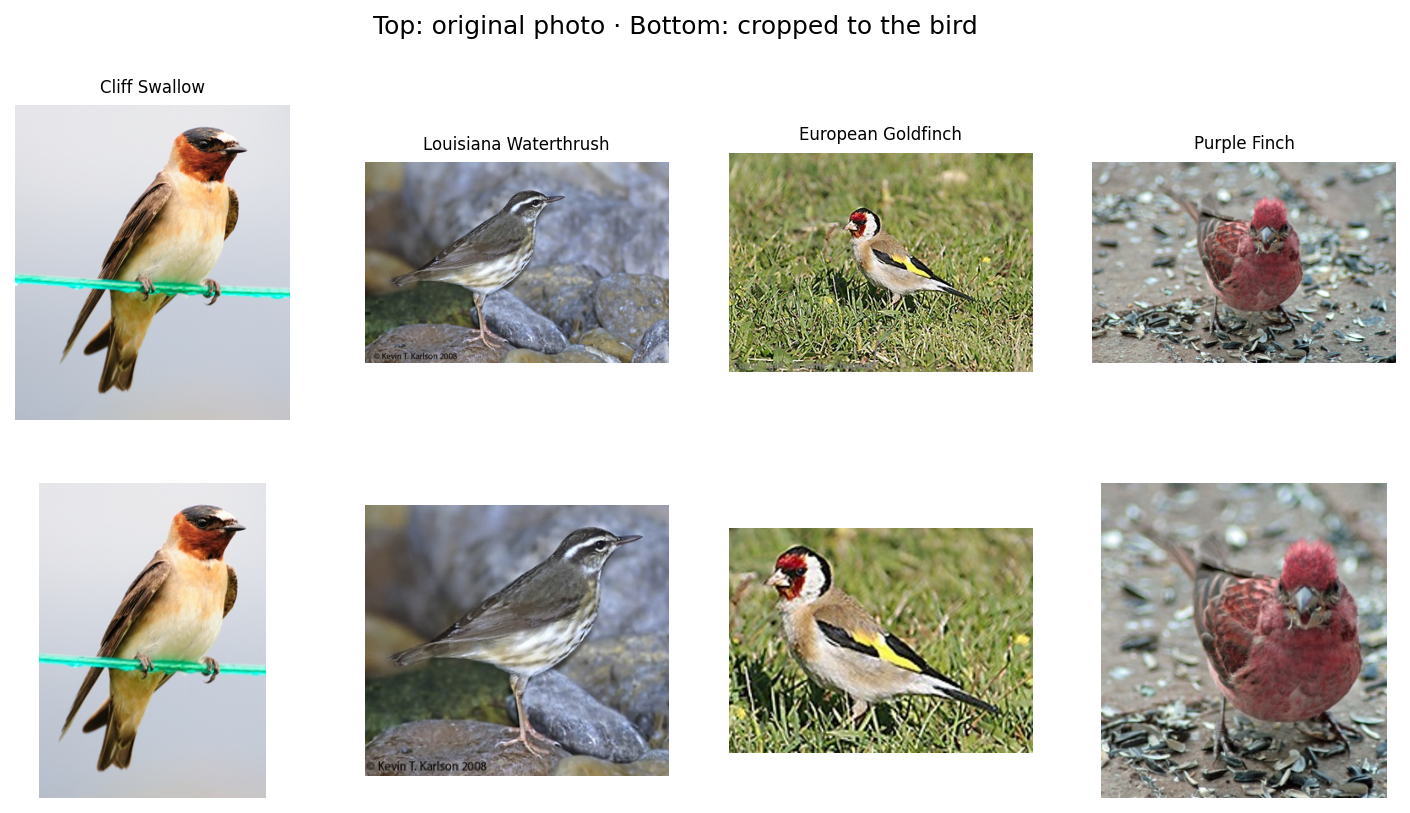

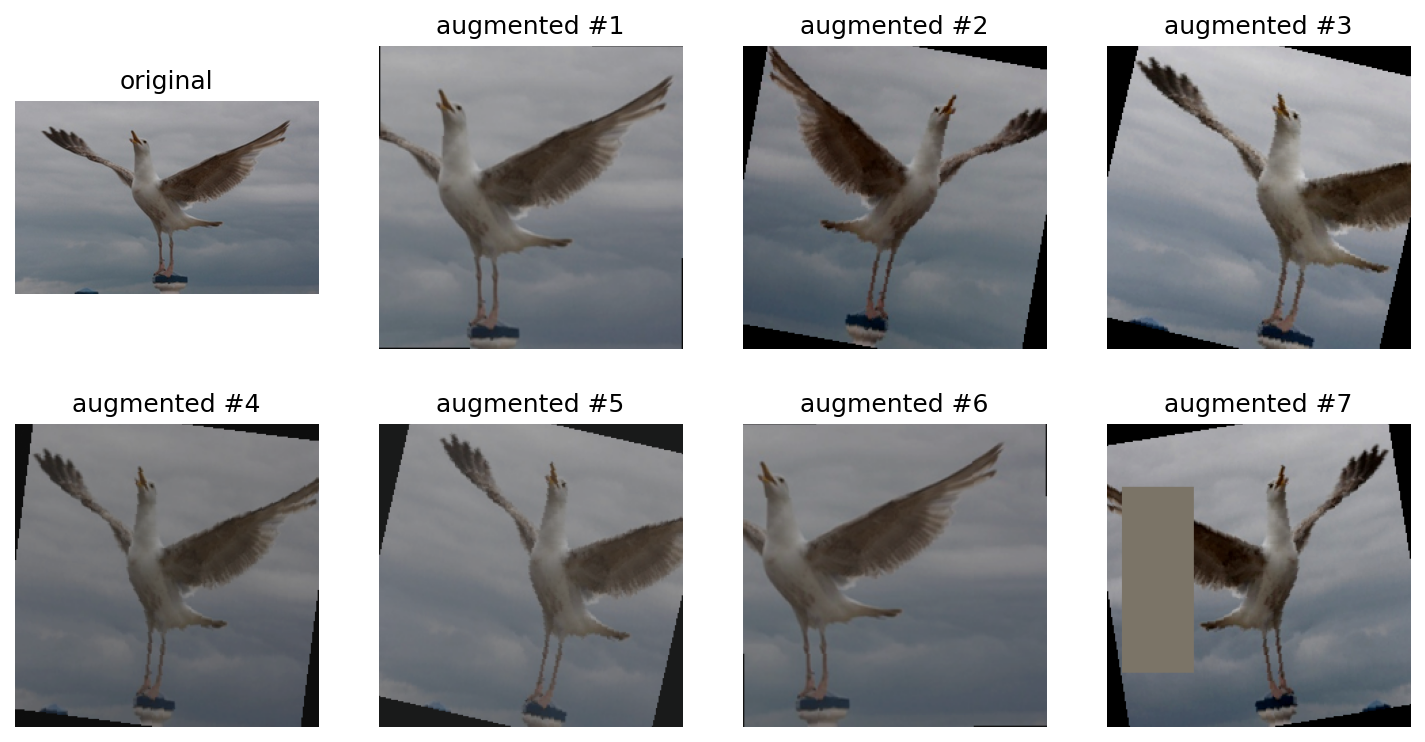

In [4]:
EXECUTED = PROCESSED / "_executed"
run([sys.executable, "-m", "jupyter", "nbconvert", "--to", "notebook", "--execute", "--output-dir", EXECUTED,
     "notebooks/05_image_preparation.ipynb"])

executed = json.loads((EXECUTED / "05_image_preparation.ipynb").read_text())
for cell in executed["cells"]:
    for out in cell.get("outputs", []):
        if out.get("name") == "stdout":
            print("".join(out["text"]).strip())
if IN_COLAB:
    shutil.copy(EXECUTED / "05_image_preparation.ipynb", OUT / "05_image_preparation_executed.ipynb")
for name in ("05_crop_examples", "05_augmentation_examples"):
    display(ShowImage(filename=str(ROOT / "documentation" / "figures" / f"{name}.png"), width=800))

## 5. Splits, transforms and loaders from `scripts/augmentation.py`

The same `make_splits`, `train_transform`, `eval_transform` and `BirdImages` that `05` checks and shows, imported unchanged. Only the loader settings (batch size, worker processes) are chosen here, for speed on the GPU.

In [5]:
from augmentation import (BirdImages, make_splits, train_transform, eval_transform,
                          IMG_SIZE, N_CLASSES, RANDOM_STATE)

assert IMG_SIZE == CONFIG["img_size"]
train_df, val_df, test_df = make_splits(CSV)
if SMOKE_TEST:   # 10 species, a few photos each
    pick = lambda df, n: df[df.class_id <= 10].groupby("class_id").head(n)
    train_df, val_df, test_df = pick(train_df, 4), pick(val_df, 2), pick(test_df, 3)
full_train_df = pd.concat([train_df, val_df])     # all official training photos, for the final retrain
assert not set(full_train_df.image_id) & set(test_df.image_id)
assert not set(train_df.image_id) & set(val_df.image_id)

NUM_WORKERS = 0 if SMOKE_TEST else min(12, os.cpu_count() or 2)

def make_loader(df, train):
    return DataLoader(BirdImages(df, PROCESSED, train_transform if train else eval_transform),
                      batch_size=BATCH_SIZE, shuffle=train, drop_last=train, num_workers=NUM_WORKERS,
                      pin_memory=DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0,
                      generator=torch.Generator().manual_seed(RANDOM_STATE) if train else None)

species = (pd.read_csv(CSV)[["class_id", "species"]].drop_duplicates()
           .set_index("class_id").sort_index().species.tolist())       # index = class_id - 1
print(f"train {len(train_df):,} | val {len(val_df):,} | all training {len(full_train_df):,} | "
      f"test {len(test_df):,} photos | input {IMG_SIZE} px | {NUM_WORKERS} loader workers")

train 4,795 | val 1,199 | all training 5,994 | test 5,794 photos | input 224 px | 12 loader workers


## 6. Model and training code

- **ViT-B/16** from torchvision with the ImageNet weights. Its 1,000-class head (`model.heads`) is replaced by a new linear layer 768 → 200, which starts from random weights. Everything else starts from ImageNet.
- **Same input as the CNNs:** the weights' own preprocessing is printed next to the team's `eval_transform`; both resize to 256, crop the centre 224 px and use the ImageNet mean and standard deviation, so the ViT sees the photos exactly as ResNet-50 does.
- **Same loop as the ResNet-50 notebooks:** SGD with momentum 0.9, the new head at 10× the learning rate, warm-up then cosine decay, label smoothing 0.1, mixed precision, resumable checkpoints, and accuracy, macro-F1 and top-5 accuracy.
- **Gradient clipping (new):** early in fine-tuning a transformer can take the odd very large step that undoes the pretraining. Limiting the gradient norm to 1 stops that, as in the ViT paper. With mixed precision the gradients are unscaled first, so the limit applies to the real gradient.

In [6]:
from torchvision.models import vit_b_16, ViT_B_16_Weights
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)

def autocast():
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP)

def new_model():
    torch.manual_seed(RANDOM_STATE)
    model = vit_b_16(weights=ViT_B_16_Weights[WEIGHTS] if WEIGHTS else None, progress=False)
    model.heads = nn.Sequential(nn.Linear(model.hidden_dim, N_CLASSES))   # new 200-way head (random weights)
    return model.to(DEVICE, memory_format=torch.channels_last)


_m = vit_b_16(weights=None)
_m.heads = nn.Sequential(nn.Linear(_m.hidden_dim, N_CLASSES))
print(f"ViT-B/16: {len(_m.encoder.layers)} layers, {_m.hidden_dim} wide, patches {_m.patch_size}x{_m.patch_size} px "
      f"-> {(224 // _m.patch_size) ** 2} patches + [CLS], {sum(p.numel() for p in _m.parameters()):,} weights")
del _m
if WEIGHTS:
    print("ViT weights' own preprocessing:", ViT_B_16_Weights[WEIGHTS].transforms())
print("Team eval_transform:            ", eval_transform)

def new_optimiser(model, lr_backbone, steps_per_epoch):
    head = list(model.heads.parameters())
    head_ids = {id(p) for p in head}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    optimizer = torch.optim.SGD([{"params": backbone, "lr": lr_backbone},
                                 {"params": head, "lr": lr_backbone * HEAD_LR_MULT}],
                                momentum=0.9, nesterov=True, weight_decay=WEIGHT_DECAY)
    steps, warmup = EPOCHS * steps_per_epoch, WARMUP_EPOCHS * steps_per_epoch
    def lr_factor(step):
        if step < warmup:
            return (step + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, steps - warmup)))
    return optimizer, torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)

def train_one_epoch(model, loader, optimizer, scheduler, scaler):
    model.train()
    loss_sum, correct, seen = 0.0, 0, 0
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True, memory_format=torch.channels_last)
        y = y.to(DEVICE, non_blocking=True)
        with autocast():
            logits = model(x)
            loss = criterion(logits, y)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)                         # real gradients, so the clip applies to them
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        loss_sum += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        seen += len(y)
    return loss_sum / seen, correct / seen

@torch.no_grad()
def predict(model, loader):
    """Class probabilities, true labels (0-199) and mean cross-entropy (without smoothing)."""
    model.eval()
    probs, labels, loss_sum = [], [], 0.0
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True, memory_format=torch.channels_last)
        y = y.to(DEVICE, non_blocking=True)
        with autocast():
            logits = model(x)
        loss_sum += nn.functional.cross_entropy(logits.float(), y, reduction="sum").item()
        probs.append(logits.float().softmax(1).cpu())
        labels.append(y.cpu())
    probs, labels = torch.cat(probs).numpy(), torch.cat(labels).numpy()
    return probs, labels, loss_sum / len(labels)

def scores(probs, labels):
    preds = probs.argmax(1)
    return {"accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro"),
            "top5_accuracy": top_k_accuracy_score(labels, probs, k=5, labels=np.arange(N_CLASSES))}

def save_atomic(obj, path):
    tmp = path.with_suffix(".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)

def fit(run_name, train_rows, val_rows, lr_backbone):
    """Train one run (resumable). With validation rows, keep the epoch with the best validation macro-F1;
    without, keep the last epoch. Returns the epoch history and a summary; the kept weights are in <run>_best.pt."""
    config = {**CONFIG, "run": run_name, "lr_backbone": lr_backbone, "train_photos": len(train_rows)}
    last, best_path = CKPT_DIR / f"{run_name}_last.pt", CKPT_DIR / f"{run_name}_best.pt"
    train_loader = make_loader(train_rows, train=True)
    val_loader = make_loader(val_rows, train=False) if val_rows is not None else None
    model = new_model()
    optimizer, scheduler = new_optimiser(model, lr_backbone, len(train_loader))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    start, history, best = 0, [], {"epoch": 0, "val": None}
    if last.exists():
        ckpt = torch.load(last, map_location=DEVICE, weights_only=False)
        if ckpt["config"] != config:
            raise ValueError(f"{last.name} was saved with different settings - delete it to start this run again")
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        scaler.load_state_dict(ckpt["scaler"])
        start, history, best = ckpt["epoch"] + 1, ckpt["history"], ckpt["best"]
        print(f"{run_name}: resuming after epoch {start}" if start < EPOCHS else f"{run_name}: already finished")

    for epoch in range(start, EPOCHS):
        t0 = time.time()
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, scheduler, scaler)
        row = {"epoch": epoch + 1, "train_loss": train_loss, "train_accuracy": train_acc}
        if val_loader is not None:
            val_probs, val_labels, val_loss = predict(model, val_loader)
            val = scores(val_probs, val_labels)
            row.update(val_loss=val_loss, **{f"val_{k}": v for k, v in val.items()})
        row["seconds"] = time.time() - t0
        history.append(row)
        keep = val_loader is None or best["val"] is None or val["macro_f1"] > best["val"]["macro_f1"]
        if keep:
            best = {"epoch": epoch + 1, "val": val if val_loader is not None else None}
            save_atomic({"model": model.state_dict(), "config": config, **best}, best_path)
        save_atomic({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                     "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch,
                     "history": history, "best": best, "config": config}, last)
        msg = f"{run_name} | epoch {epoch + 1:>2}/{EPOCHS} | train loss {train_loss:.3f} acc {train_acc:.3f}"
        if val_loader is not None:
            msg += (f" | val loss {val_loss:.3f} acc {val['accuracy']:.3f} macro-F1 {val['macro_f1']:.3f}"
                    f" top-5 {val['top5_accuracy']:.3f}")
        print(msg + f" | {row['seconds']:.0f}s" + ("  *" if keep and val_loader is not None else ""), flush=True)

    history = pd.DataFrame(history)
    history.to_csv(OUT / f"{run_name}_history.csv", index=False)
    del model, optimizer, scheduler
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return history, {"run": run_name, "lr_backbone": lr_backbone, "best_epoch": best["epoch"], "val": best["val"],
                     "train_minutes": round(history.seconds.sum() / 60, 1)}

ViT-B/16: 12 layers, 768 wide, patches 16x16 px -> 196 patches + [CLS], 85,952,456 weights
ViT weights' own preprocessing: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Team eval_transform:             Compose(
      ToImage()
      Resize(size=[256], interpolation=bilinear, antialias=True)
      CenterCrop(size=(224, 224))
      ToDtype(scale=True)
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
)


## 7. Select the learning rate (train on 80%, score on validation)

One run per backbone learning rate in `LR_GRID`, each scored on the validation photos after every epoch.

In [7]:
selection = {lr: fit(f"{BASE_NAME}_lr{lr:g}", train_df, val_df, lr) for lr in LR_GRID}

selection_table = pd.DataFrame([{"backbone lr": lr, "run": s["run"], "best epoch": s["best_epoch"],
                                 "val accuracy": s["val"]["accuracy"], "val macro-F1": s["val"]["macro_f1"],
                                 "val top-5": s["val"]["top5_accuracy"], "minutes": s["train_minutes"]}
                                for lr, (_, s) in selection.items()])
BEST_LR = max(selection, key=lambda lr: selection[lr][1]["val"]["macro_f1"])
print(f"Chosen backbone learning rate: {BEST_LR:g}")
if BEST_LR in (min(LR_GRID), max(LR_GRID)) and len(LR_GRID) > 1:
    print("Note: the best rate is at the edge of LR_GRID, so a rate outside the grid might do better.")
selection_table.round(4)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth
vit_b16_224px_lr0.0005: already finished
vit_b16_224px_lr0.001: already finished
vit_b16_224px_lr0.003: already finished
Chosen backbone learning rate: 0.003
Note: the best rate is at the edge of LR_GRID, so a rate outside the grid might do better.


,backbone lr,run,best epoch,val accuracy,val macro-F1,val top-5,minutes
0,0.0005,vit_b16_224px_lr0.0005,24,0.6030,0.5819,0.8749,12.4
1,0.0010,vit_b16_224px_lr0.001,23,0.7039,0.6962,0.9266,12.4
2,0.0030,vit_b16_224px_lr0.003,21,0.7923,0.7890,0.9525,12.4


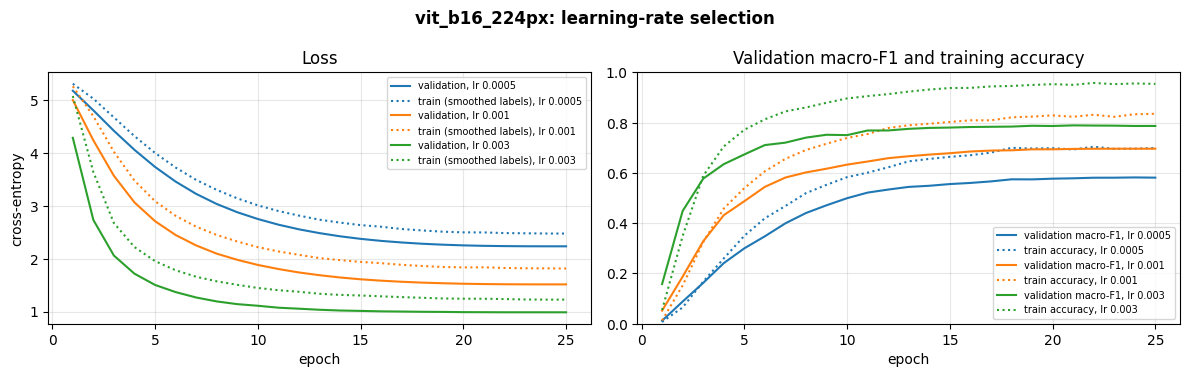

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for lr, (hist, s) in selection.items():
    line, = axes[0].plot(hist.epoch, hist.val_loss, label=f"validation, lr {lr:g}")
    axes[0].plot(hist.epoch, hist.train_loss, ":", color=line.get_color(), label=f"train (smoothed labels), lr {lr:g}")
    line, = axes[1].plot(hist.epoch, hist.val_macro_f1, label=f"validation macro-F1, lr {lr:g}")
    axes[1].plot(hist.epoch, hist.train_accuracy, ":", color=line.get_color(), label=f"train accuracy, lr {lr:g}")
axes[0].set(title="Loss", xlabel="epoch", ylabel="cross-entropy")
axes[1].set(title="Validation macro-F1 and training accuracy", xlabel="epoch", ylim=(0, 1))
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
fig.suptitle(f"{BASE_NAME}: learning-rate selection", fontweight="bold")
plt.tight_layout()
fig.savefig(FIGURES / f"{BASE_NAME}_curves.png", dpi=150, bbox_inches="tight")
plt.show()

A widening gap between training accuracy and validation macro-F1 means the network is memorising the training photos (overfitting). Validation macro-F1 levelling off shows where more epochs stop helping.

## 8. Final model (retrain on all training photos)

Once the learning rate is chosen the validation photos are not needed any more, so the final model is trained again from the ImageNet weights on all 5,994 training photos (~25% more photos per species), and the last epoch is kept.

In [9]:
FINAL_NAME = f"{BASE_NAME}_final"
final_history, final_summary = fit(FINAL_NAME, full_train_df, None, BEST_LR)
print(f"Final model: {FINAL_NAME} ({final_summary['train_minutes']} min)")

vit_b16_224px_final: already finished
Final model: vit_b16_224px_final (14.1 min)


## 9. Final test evaluation (run once)

The final model is scored once on the 5,794 official test photos, then compared with the attribute-based models and every ResNet-50, baseline CNN and ViT run whose results file is in `results/` (or in the Drive folder on Colab).

In [10]:
model = new_model()
final_ckpt = torch.load(CKPT_DIR / f"{FINAL_NAME}_best.pt", map_location=DEVICE, weights_only=False)
model.load_state_dict(final_ckpt["model"])
test_probs, test_labels, test_loss = predict(model, make_loader(test_df, train=False))
test = scores(test_probs, test_labels)

results = {"run": FINAL_NAME, "config": {**CONFIG, "lr_backbone": BEST_LR, "final_retrain": True},
           "selection": selection_table.to_dict("records"), "final_epoch": final_ckpt["epoch"],
           "test": test, "test_photos": int(len(test_labels)),
           "train_minutes_total": round(sum(s["train_minutes"] for _, s in selection.values())
                                        + final_summary["train_minutes"], 1)}
(OUT / f"{FINAL_NAME}_results.json").write_text(json.dumps(results, indent=2))

per_class = pd.DataFrame({"class_id": np.arange(1, N_CLASSES + 1), "species": species,
                          "f1": f1_score(test_labels, test_probs.argmax(1), average=None, labels=np.arange(N_CLASSES))})
per_class.to_csv(OUT / f"{FINAL_NAME}_per_class_f1.csv", index=False)
print(f"{FINAL_NAME} | test accuracy {test['accuracy']:.4f} | macro-F1 {test['macro_f1']:.4f} | "
      f"top-5 {test['top5_accuracy']:.4f}")

# Attribute-based results on the same official test split (from the notebooks named), then every image model
# whose results file is in results/ (cloned from the repo) or in this notebook's output folder
rows = [("k-NN, tuned (knn.ipynb)", "312 attributes", 0.347, 0.342, 0.629),
        ("k-NN + LDA, certainty-weighted (knn_improvements.ipynb)", "312 attributes", 0.442, 0.416, 0.702),
        ("Random forest, tuned (randomForest.ipynb)", "312 attributes", 0.4563, 0.4349, 0.7206),
        ("RF + logistic regression ensemble (randomForestOptimisation.ipynb)", "attributes + aggregates",
         0.5104, 0.5059, 0.7656)]
seen = set()
for path in sorted(ROOT.glob("results/*/*_results.json")) + sorted(OUT.glob("*_results.json")):
    r = json.loads(path.read_text())
    if r["run"] in seen or "smoke" in r["run"]:
        continue
    seen.add(r["run"])
    rows.append((r["run"], "photos", r["test"]["accuracy"], r["test"]["macro_f1"], r["test"]["top5_accuracy"]))
if not any(name.startswith("base_cnn") for name in seen):   # not merged into main yet: numbers from the base-cnn branch
    rows.append(("base_cnn_4blocks_224px_final (base-cnn branch)", "photos", 0.5704, 0.5697, 0.8336))
comparison = pd.DataFrame(rows, columns=["model", "input", "test accuracy", "test macro-F1", "test top-5"])
comparison.round(4)

vit_b16_224px_final | test accuracy 0.8202 | macro-F1 0.8195 | top-5 0.9624


,model,input,test accuracy,test macro-F1,test top-5
0,"k-NN, tuned (knn.ipynb)",312 attributes,0.3470,0.3420,0.6290
1,"k-NN + LDA, certainty-weighted (knn_improvemen...",312 attributes,0.4420,0.4160,0.7020
2,"Random forest, tuned (randomForest.ipynb)",312 attributes,0.4563,0.4349,0.7206
3,RF + logistic regression ensemble (randomFores...,attributes + aggregates,0.5104,0.5059,0.7656
4,resnet50_altered_224px_final,photos,0.8032,0.8011,0.9417
5,resnet50_pretrained_224px,photos,0.7637,0.7640,0.9351
6,resnet50_pretrained_448px_final,photos,0.8188,0.8179,0.9496
7,vit_b16_224px_final,photos,0.8202,0.8195,0.9624
8,base_cnn_4blocks_224px_final,photos,0.5704,0.5697,0.8336
9,base_cnn_4blocks_448px_final,photos,0.5704,0.5695,0.8226


## 10. Which species does it confuse?

The most frequent test mistakes, as (true species → predicted species).

In [11]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(test_labels, test_probs.argmax(1), labels=np.arange(N_CLASSES))
np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(cm, axis=None)[::-1][:10], cm.shape))[0]
print(pd.DataFrame([(species[t], species[p], cm[t, p], int((test_labels == t).sum())) for t, p in top],
                   columns=["true species", "predicted as", "mistakes", "test photos of true species"]).to_string())

          true species          predicted as  mistakes  test photos of true species
0        Forsters Tern           Common Tern        12                           30
1      California Gull      Ring billed Gull        11                           30
2   Long tailed Jaeger       Pomarine Jaeger        10                           30
3    Loggerhead Shrike     Great Grey Shrike        10                           30
4          Common Tern            Artic Tern        10                           30
5      California Gull          Western Gull         9                           30
6         Elegant Tern          Caspian Tern         8                           30
7       Brewer Sparrow  Clay colored Sparrow         7                           29
8  Red faced Cormorant     Pelagic Cormorant         7                           22
9           Artic Tern           Common Tern         6                           29


## 11. What does the ViT look at? (attention rollout)

Each of the 12 layers has attention weights saying how much every token takes from every other token. **Attention rollout** (Abnar and Zuidema, 2020) multiplies them through the layers to estimate how much each of the 196 patches contributes to the [CLS] token that makes the prediction. Bright areas are the patches the model draws most information from.

This is a picture of where information flows, not proof of why the model decided what it did, so it is used here only to check that the model attends to the bird rather than the background. The photos shown are the first test photo of a few species from the confusion analyses (raven and crow among them), when present.

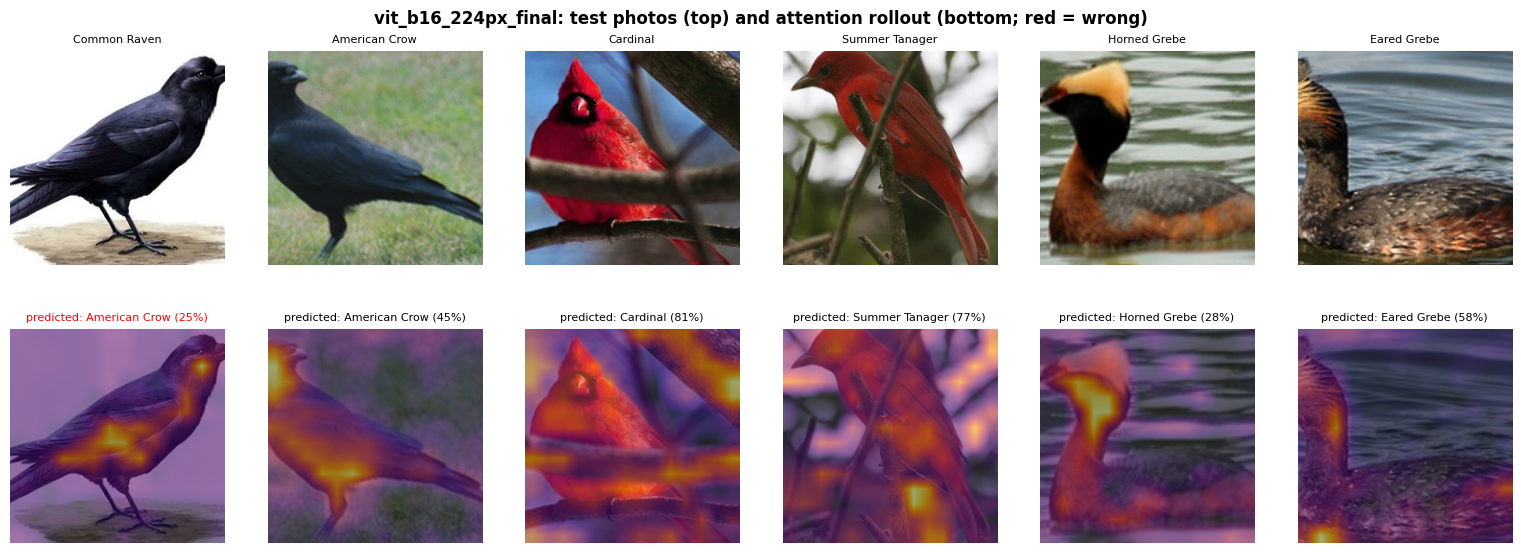

In [12]:
from augmentation import IMAGENET_MEAN, IMAGENET_STD, BirdImages as _Images


@torch.no_grad()
def attention_rollout(model, x):
    """[CLS]-to-patch attention combined over all layers (Abnar & Zuidema, 2020). Returns (batch, 14, 14)."""
    captured = []
    hooks = [blk.ln_1.register_forward_hook(lambda m, i, o: captured.append(o)) for blk in model.encoder.layers]
    model(x)
    for h in hooks:
        h.remove()
    eye = None
    roll = None
    for blk, h in zip(model.encoder.layers, captured):
        _, w = blk.self_attention(h, h, h, need_weights=True, average_attn_weights=True)   # (batch, 197, 197)
        w = w.float()
        eye = torch.eye(w.shape[-1], device=w.device) if eye is None else eye
        a = 0.5 * w + 0.5 * eye                       # the skip connection keeps half of each token
        a = a / a.sum(-1, keepdim=True)
        roll = a if roll is None else a @ roll
    cls = roll[:, 0, 1:]                              # how much each patch reaches the [CLS] token
    side = int(cls.shape[-1] ** 0.5)
    cls = cls.reshape(-1, side, side)
    return cls / cls.amax(dim=(1, 2), keepdim=True)


wanted = ["Common Raven", "American Crow", "Cardinal", "Summer Tanager", "Horned Grebe", "Eared Grebe"]
picks = [test_df.index[test_df.species == s][0] for s in wanted if (test_df.species == s).any()]
picks = (picks + [i for i in test_df.index if i not in picks])[:6]
show = _Images(test_df.loc[picks], PROCESSED, eval_transform)
x = torch.stack([show[i][0] for i in range(len(picks))]).to(DEVICE)
model.eval()
maps = nn.functional.interpolate(attention_rollout(model, x)[:, None], size=x.shape[-2:], mode="bilinear")[:, 0].cpu()
with torch.no_grad():
    pred = model(x).float().softmax(1).cpu()

mean, std = torch.tensor(IMAGENET_MEAN)[:, None, None], torch.tensor(IMAGENET_STD)[:, None, None]
fig, axes = plt.subplots(2, len(picks), figsize=(2.6 * len(picks), 5.6))
axes = np.array(axes).reshape(2, -1)
for j, i in enumerate(picks):
    img = (x[j].cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    true_name, p = test_df.loc[i, "species"], pred[j].argmax().item()
    axes[0, j].imshow(img)
    axes[0, j].set_title(f"{true_name}", fontsize=8)
    axes[1, j].imshow(img)
    axes[1, j].imshow(maps[j], cmap="inferno", alpha=0.6)
    axes[1, j].set_title(f"predicted: {species[p]} ({pred[j, p]:.0%})", fontsize=8,
                         color="black" if species[p] == true_name else "red")
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle(f"{FINAL_NAME}: test photos (top) and attention rollout (bottom; red = wrong)", fontweight="bold")
plt.tight_layout()
fig.subplots_adjust(hspace=0.3)
fig.savefig(FIGURES / f"{FINAL_NAME}_attention.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. ViT vs ResNet-50, species by species

Same photos, same pipeline, same loop: the per-species test F1 of this ViT next to `resnet50_altered_224px` (the ResNet-50 run on the team's standard 224 px pipeline). The species that change most show where attention over the whole photo helps or hurts compared with convolutions.

In [13]:
ref = ROOT / "results" / "resnet50" / "resnet50_altered_224px_final_per_class_f1.csv"
if ref.exists():
    both = per_class.merge(pd.read_csv(ref)[["class_id", "f1"]], on="class_id", suffixes=("_vit", "_resnet50"))
    both["change"] = both.f1_vit - both.f1_resnet50
    print(f"ViT better on {(both.change > 0).sum()} species, worse on {(both.change < 0).sum()}, "
          f"equal on {(both.change == 0).sum()} | mean F1 ViT {both.f1_vit.mean():.3f} vs ResNet-50 {both.f1_resnet50.mean():.3f}")
    cols = ["species", "f1_resnet50", "f1_vit", "change"]
    display(pd.concat([both[both.change > 0].nlargest(8, "change")[cols].assign(side="ViT better"),
                       both[both.change < 0].nsmallest(8, "change")[cols].assign(side="ResNet-50 better")]).round(3))
else:
    print(f"{ref.relative_to(ROOT)} not found, so there is nothing to compare with")

ViT better on 116 species, worse on 69, equal on 15 | mean F1 ViT 0.820 vs ResNet-50 0.801


,species,f1_resnet50,f1_vit,change,side
136,Cliff Swallow,0.613,0.847,0.235,ViT better
21,Chuck will Widow,0.642,0.863,0.221,ViT better
63,Ring billed Gull,0.459,0.667,0.208,ViT better
104,Whip poor Will,0.652,0.850,0.198,ViT better
142,Caspian Tern,0.393,0.567,0.173,ViT better
24,Pelagic Cormorant,0.431,0.597,0.166,ViT better
70,Long tailed Jaeger,0.417,0.582,0.165,ViT better
61,Herring Gull,0.423,0.556,0.132,ViT better
117,House Sparrow,0.774,0.582,-0.192,ResNet-50 better
44,Northern Fulmar,0.769,0.642,-0.128,ResNet-50 better


## 13. Save per-photo probabilities (for the consolidation)

The consolidation notebook (`consolidation.ipynb`) combines this model with the attribute model photo by photo, so it needs the **probability of each species for each photo**, not only the overall scores. Two files are saved:

- **Validation photos (1,199):** predicted by the selection run with the chosen learning rate, at its last epoch. That model was trained on the other 80% of the training photos only, so these predictions are fair for choosing how to combine the models. The final model has seen these photos, so it cannot be used here.
- **Test photos (5,794):** the final model's predictions from section 9, saved as they are.

If the checkpoints are still in Drive, "Run all" skips the finished training runs and only predicts, which takes a few minutes. Run this before section 15 deletes the checkpoints.

In [14]:
SEL_NAME = f"{BASE_NAME}_lr{BEST_LR:g}"
sel_path = CKPT_DIR / f"{SEL_NAME}_last.pt"
assert sel_path.exists(), f"{sel_path.name} is missing (deleted?): run section 7 again to recreate it"

sel_model = new_model()
sel_ckpt = torch.load(sel_path, map_location=DEVICE, weights_only=False)
sel_model.load_state_dict(sel_ckpt["model"])
val_probs, val_labels, _ = predict(sel_model, make_loader(val_df, train=False))
assert (val_labels + 1 == val_df.class_id.values).all() and (test_labels + 1 == test_df.class_id.values).all()

np.savez_compressed(OUT / f"{BASE_NAME}_val_probs.npz", image_id=val_df.image_id.values,
                    class_id=val_df.class_id.values, probs=val_probs.astype(np.float32),
                    model=SEL_NAME, epoch=sel_ckpt["epoch"])
np.savez_compressed(OUT / f"{FINAL_NAME}_test_probs.npz", image_id=test_df.image_id.values,
                    class_id=test_df.class_id.values, probs=test_probs.astype(np.float32), model=FINAL_NAME)
print(f"validation: {SEL_NAME}, epoch {sel_ckpt['epoch']}, {len(val_df):,} photos | {scores(val_probs, val_labels)}")
print(f"test: {FINAL_NAME}, {len(test_df):,} photos | {scores(test_probs, test_labels)}")
del sel_model
if DEVICE == "cuda":
    torch.cuda.empty_cache()

validation: vit_b16_224px_lr0.003, epoch 24, 1,199 photos | {'accuracy': 0.7906588824020017, 'macro_f1': 0.7867092490842491, 'top5_accuracy': np.float64(0.950792326939116)}
test: vit_b16_224px_final, 5,794 photos | {'accuracy': 0.8201587849499482, 'macro_f1': 0.8195084939795575, 'top5_accuracy': np.float64(0.9623748705557473)}


## 14. Files written

All in `MyDrive/f20dl_resnet50/` on Colab (`results/vit/` locally). To commit them, download them from Drive into `results/vit/` (and `results/vit/figures/`) in the repo.
- `vit_b16_224px_final_results.json`: settings, learning-rate selection, test scores
- `vit_b16_224px_*_history.csv`: one row per epoch for every run
- `vit_b16_224px_final_per_class_f1.csv`: test F1 for each species
- `vit_b16_224px_val_probs.npz`, `vit_b16_224px_final_test_probs.npz`: species probabilities for every validation and test photo (section 13)
- `figures/vit_b16_224px_curves.png`: learning curves
- `figures/vit_b16_224px_final_attention.png`: attention rollout on six test photos
- `05_image_preparation_executed.ipynb` (Colab only): the executed pipeline notebook with its checks

The `checkpoints/` folder and the `cub_processed_*.zip` cache are large and only needed on Colab: they are not committed.

## 15. Free the Drive space (optional)

The ViT checkpoints take 4 to 5 GB. Once the files above are saved, set `DELETE_CHECKPOINTS = True` and run this cell to delete this notebook's checkpoints (the photo cache and the other notebooks' checkpoints are kept). Deleting them means a later "Run all" trains everything again.

In [15]:
DELETE_CHECKPOINTS = False

mine = sorted(CKPT_DIR.glob(f"{BASE_NAME}_*.pt"))
print(f"{len(mine)} checkpoints, {sum(p.stat().st_size for p in mine) / 1e9:.1f} GB")
if DELETE_CHECKPOINTS:
    for p in mine:
        p.unlink()
    print("deleted")

8 checkpoints, 4.1 GB


In [ ]:
if IN_COLAB:
    time.sleep(15)  # allow Google Drive FUSE cache to finish flushing files
    from google.colab import runtime
    runtime.unassign()